# A worked example with published data: the local flow curve of a foam

Does a three-dimensional aqueous foam have a continuous Herschel–Bulkley (HB) flow curve down to vanishing shear rate, or does it stop flowing below a finite **critical shear rate** $\dot\gamma_c$, as thixotropic materials do? Ovarlez, Krishan and Cohen-Addad (2010) answered this with magnetic resonance imaging (MRI) velocimetry in a wide-gap Couette cell: the local stress and local shear rate measured across the gap fall on one curve. Their published figure contains 152 local (rate, stress) points, which the review digitized and reanalyzed (Supplementary Note S2). This notebook walks through that reanalysis with simple tools: least-squares fits of three models, the linear reduction that exposes the $\sigma_y$–$n$ valley, the stored errors-in-variables results, what the data say about $\dot\gamma_c$, and what digitized data can and cannot support.

### Where this is in the review
* **Supplementary Note S2**, "Local flow curve of a foam: critical shear rate and parameter intervals": error model **Eq. (S4)**, model comparison **Table SI**, **Fig. S1** (script `scripts/figS1_foam_reanalysis.py`).
* Article **Sec. V B** (simple versus thixotropic yield-stress fluids and $\dot\gamma_c$), **Sec. V C** (the foam exponent, $n\approx0.36$ versus 0.46), **Sec. VI D** (identifiability of the HB triplet), **Sec. VI E** (systematic error), **Sec. IX A** ("Is the measured flow curve the local law?") and row A of **Table XII**; the Bingham and Casson laws are in **Table X**.
* Data: `data/foam_sles_fig3b_digitized.csv` (the 152 points), `data/foam_reanalysis_results.json` (stored results of the errors-in-variables reanalysis), `data/foam_digitization_provenance.json`, `data/foam_selection_audit.json`, and the plotted series in `data/figure_data/figS1_foam.csv`.

### Learning objectives
1. Fit the HB, Bingham and Casson models to a real local flow curve and compare them with an information criterion.
2. Use the fact that HB is linear in $(\sigma_y, K)$ at fixed $n$ to map the $\sigma_y$–$n$ valley and obtain profile intervals.
3. Explain the errors-in-variables model of Note S2 and why it changes little here.
4. State what a critical shear rate is, and how a flow curve alone bounds it.
5. List the limits of conclusions drawn from digitized published data.

In [1]:
# Standard set-up used by every notebook in this folder.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not leave compiled files in scripts/

# Plot style and palette of the article. hbstyle also defines save(), which rewrites the
# published figures and data: it is deliberately NOT imported or called here.
from hbstyle import C
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110})


def figure_series(df, panel, series):
    """x and y of one plotted series in a data/figure_data/<figure>.csv table."""
    s = df[(df["panel"] == panel) & (df["series"] == series)].sort_values("index")
    if s.empty:
        raise KeyError(f"no series {series!r} in panel {panel!r}")
    return s["x"].to_numpy(float), s["y"].to_numpy(float)

import json
from scipy.optimize import least_squares, minimize, minimize_scalar

## 1. The data

The points are the centers of the published vector markers of Fig. 3b of Ovarlez, Krishan and Cohen-Addad (2010) (arXiv:1007.4133v2), converted to physical units with the axis calibration stored in the provenance file. They are plot-derived values, not the raw MRI and torque data. Each marker shape is one acquisition series (a rotation rate or a shear history); which shape corresponds to which rotation rate is not recoverable because the source figure has no speed legend.

The foam: SLES/betaine/glycerol, gas fraction 92%, mean bubble diameter 45 µm, wide-gap Couette cell with roughened walls (radii 4.1 and 6 cm), 5–100 rpm, $21\pm1$ °C.

In [2]:
foam = pd.read_csv(DATA / "foam_sles_fig3b_digitized.csv")
rate = foam["shear_rate_s_inv"].to_numpy()        # local shear rate (1/s)
stress = foam["stress_Pa"].to_numpy()             # local shear stress (Pa)
group = foam["group"].to_numpy()                  # marker shape = acquisition series
N = len(rate)
series_names = np.unique(group)
print(f"{N} points in {len(series_names)} series; rates {rate.min():.3f}-{rate.max():.1f} 1/s, "
      f"stresses {stress.min():.1f}-{stress.max():.1f} Pa")
print(foam.groupby("group").size().to_string())
print(f"points below 1.5 1/s: {np.sum(rate < 1.5)};  points below 0.04 1/s: {np.sum(rate < 0.04)}")

152 points in 7 series; rates 0.027-27.3 1/s, stresses 34.0-83.7 Pa
group
circle            25
diamond           23
square            26
triangle_down     17
triangle_left     23
triangle_right    16
triangle_up       22
points below 1.5 1/s: 47;  points below 0.04 1/s: 1


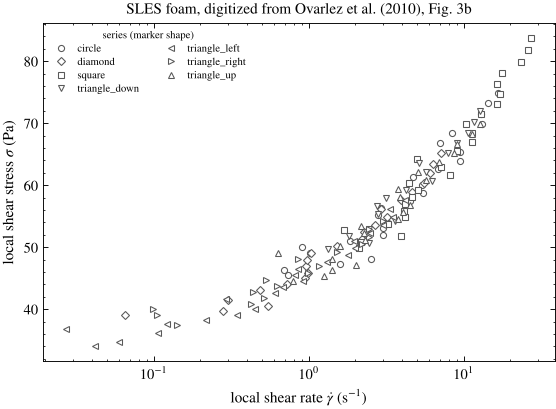

In [3]:
MARKERS = {"circle": "o", "diamond": "D", "square": "s", "triangle_down": "v",
           "triangle_left": "<", "triangle_right": ">", "triangle_up": "^"}

def plot_points(ax):
    for name in series_names:
        sel = group == name
        ax.semilogx(rate[sel], stress[sel], MARKERS[name], ms=4, mfc="white", mec="0.35", mew=0.7, label=name)

fig, ax = plt.subplots(figsize=(6, 4))
plot_points(ax)
ax.set(xlabel=r"local shear rate $\dot\gamma$ (s$^{-1}$)", ylabel=r"local shear stress $\sigma$ (Pa)",
       title="SLES foam, digitized from Ovarlez et al. (2010), Fig. 3b")
ax.legend(fontsize=7, ncol=2, title="series (marker shape)", title_fontsize=7)
plt.show()

The points span three decades of rate and lie on one smooth, concave curve: the stress rises from about 34 Pa at 0.03 s$^{-1}$ to about 84 Pa at 27 s$^{-1}$. The scatter about the curve is a few pascals.

## 2. Three models and ordinary least-squares fits

From Table X of the article:

| model | flow curve ($\sigma>\sigma_y$) | parameters |
|---|---|---|
| Herschel–Bulkley | $\sigma=\sigma_y+K\dot\gamma^{\,n}$ | $\sigma_y$, $K$, $n$ |
| Bingham | $\sigma=\sigma_y+\mu_p\dot\gamma$ | $\sigma_y$, $\mu_p$ |
| Casson | $\sqrt{\sigma}=\sqrt{\sigma_y}+\sqrt{\mu_c\dot\gamma}$ | $\sigma_y$, $\mu_c$ |

We start with the simplest estimator: ordinary least squares in stress, which assumes that only the stress is noisy, with the same standard deviation at every point, and that the points are independent. For Gaussian errors with unknown standard deviation the maximized log-likelihood is $-\tfrac N2\ln({\rm RSS}/N)$ + const, so the Akaike information criterion is
$${\rm AIC}=N\ln({\rm RSS}/N)+2k,$$
where RSS is the residual sum of squares and $k$ counts the fitted parameters including the noise level (as in Table SI). Differences of AIC between models are what matter.

In [4]:
def f_hb(p, x):      return p[0] + p[1] * x ** p[2]
def f_bingham(p, x): return p[0] + p[1] * x
def f_casson(p, x):  return (np.sqrt(p[0]) + np.sqrt(p[1] * x)) ** 2

MODELS = {  # function, start, lower bounds, upper bounds, parameter names
    "HB":      (f_hb,      [30, 15, 0.4], [0, 1e-6, 0.05], [200, 500, 2], ["sigma_y (Pa)", "K (Pa s^n)", "n"]),
    "Bingham": (f_bingham, [40, 2],       [0, 0],          [200, 100],    ["sigma_y (Pa)", "mu_p (Pa s)"]),
    "Casson":  (f_casson,  [30, 1],       [0, 0],          [200, 100],    ["sigma_y (Pa)", "mu_c (Pa s)"]),
}

ols = {}
for name, (f, p0, lo, hi, _) in MODELS.items():
    res = least_squares(lambda p: f(p, rate) - stress, p0, bounds=(lo, hi), xtol=1e-12, ftol=1e-12)
    rss = np.sum(res.fun ** 2)
    k = len(p0) + 1                                  # + noise standard deviation
    ols[name] = {"p": res.x, "rmse": np.sqrt(rss / N), "AIC": N * np.log(rss / N) + 2 * k}

aic_hb = ols["HB"]["AIC"]
for name, r in ols.items():
    pars = ", ".join(f"{lab} = {v:.4g}" for lab, v in zip(MODELS[name][4], r["p"]))
    print(f"{name:8s} {pars:55s} RMSE = {r['rmse']:.2f} Pa   dAIC = {r['AIC'] - aic_hb:6.1f}")

HB       sigma_y (Pa) = 30.32, K (Pa s^n) = 16.23, n = 0.36      RMSE = 1.77 Pa   dAIC =    0.0
Bingham  sigma_y (Pa) = 46.16, mu_p (Pa s) = 1.882               RMSE = 4.43 Pa   dAIC =  276.9
Casson   sigma_y (Pa) = 38.63, mu_c (Pa s) = 0.3895              RMSE = 2.43 Pa   dAIC =   95.1


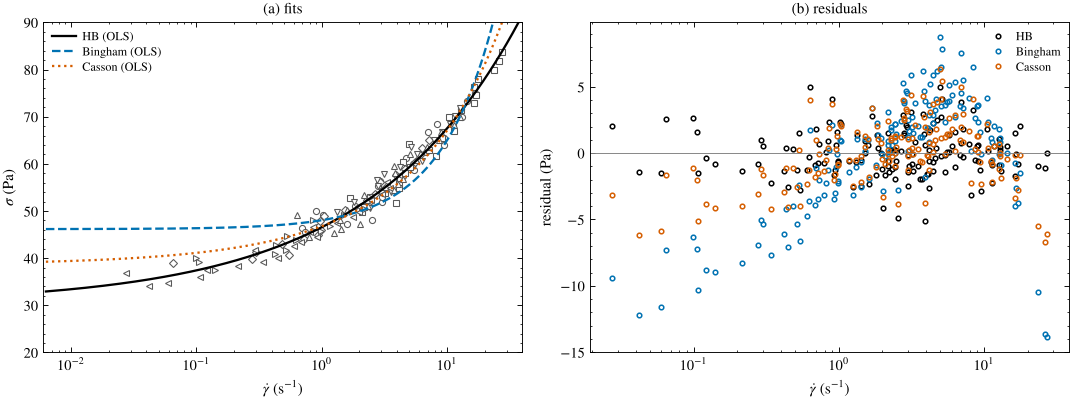

In [5]:
xx = np.logspace(-2.2, 1.6, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.9))
plot_points(ax1)
for (name, r), (col, ls) in zip(ols.items(), [("k", "-"), (C["blue"], "--"), (C["red"], ":")]):
    ax1.semilogx(xx, MODELS[name][0](r["p"], xx), color=col, ls=ls, lw=1.5, label=f"{name} (OLS)")
    ax2.semilogx(rate, stress - MODELS[name][0](r["p"], rate), "o", ms=3, color=col, mfc="none", label=name)
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[-3:], labels[-3:], fontsize=8, loc="upper left")
ax1.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", xlim=(6e-3, 40), ylim=(20, 90), title="(a) fits")
ax2.axhline(0, color="0.5", lw=0.6)
ax2.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel="residual (Pa)", title="(b) residuals")
ax2.legend(fontsize=8)
fig.tight_layout(); plt.show()

HB is decisively preferred: Casson is worse by about 95 AIC units and Bingham by about 277 (by a common rule of thumb, a difference above 10 already counts as strong evidence). The residual plot shows why: the Bingham and Casson residuals are systematic (positive in the middle of the window, negative at both ends), because a straight or square-root curve cannot follow the strong concavity of the data. The concavity also forces the Bingham line to a large intercept, about 46 Pa, roughly 50% above the HB yield stress.

## 3. The $\sigma_y$–$n$ valley: HB is linear at fixed $n$

For fixed $n$ the HB model is linear in $(\sigma_y, K)$: with $z_i=\dot\gamma_i^{\,n}$, the fit is an ordinary straight-line regression of $\sigma_i$ on $z_i$. Minimizing over $(\sigma_y,K)$ for each $n$ reduces the three-parameter fit to a one-dimensional profile in $n$ (Mullineux, 2008; article Sec. VI D). The profile shows how $\sigma_y$ and $K$ trade off as $n$ changes, and gives a **profile-likelihood interval** for $n$: the values for which the deviance $N\ln[{\rm RSS}(n)/{\rm RSS}_{\min}]$ stays below 3.84, the 95% point of $\chi^2_1$.

best n = 0.3600 (the 3-parameter OLS fit gave 0.3600)
95% profile interval: 0.326 <= n <= 0.395; sigma_y along it 28.0-32.3 Pa, K 14.2-18.6 Pa s^n


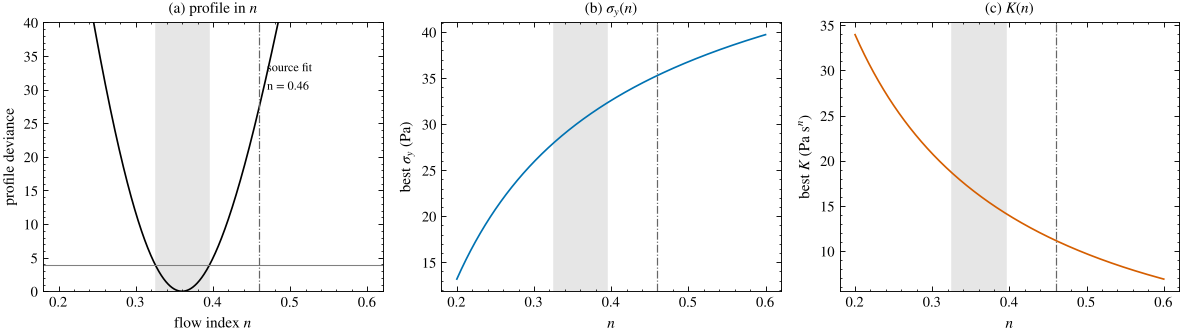

In [6]:
def linear_fit_at_n(nn, x=rate, y=stress):
    """Least-squares (sigma_y, K) at fixed n, and the residual sum of squares."""
    A = np.column_stack([np.ones_like(x), x ** nn])
    coef = np.linalg.lstsq(A, y, rcond=None)[0]
    return coef, np.sum((A @ coef - y) ** 2)

n_grid = np.linspace(0.20, 0.60, 801)
prof = np.array([[*linear_fit_at_n(nn)[0], linear_fit_at_n(nn)[1]] for nn in n_grid])
sy_n, K_n, rss_n = prof.T
dev_n = N * np.log(rss_n / rss_n.min())
inside = dev_n <= 3.841
print(f"best n = {n_grid[rss_n.argmin()]:.4f} (the 3-parameter OLS fit gave {ols['HB']['p'][2]:.4f})")
print(f"95% profile interval: {n_grid[inside].min():.3f} <= n <= {n_grid[inside].max():.3f}; "
      f"sigma_y along it {sy_n[inside].min():.1f}-{sy_n[inside].max():.1f} Pa, K {K_n[inside].min():.1f}-{K_n[inside].max():.1f} Pa s^n")

fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
ax[0].plot(n_grid, dev_n, "k"); ax[0].axhline(3.841, color="0.5", lw=0.7)
ax[0].set(xlabel="flow index $n$", ylabel="profile deviance", ylim=(0, 40), title="(a) profile in $n$")
ax[1].plot(n_grid, sy_n, color=C["blue"]); ax[1].set(xlabel="$n$", ylabel=r"best $\sigma_y$ (Pa)", title=r"(b) $\sigma_y(n)$")
ax[2].plot(n_grid, K_n, color=C["red"]); ax[2].set(xlabel="$n$", ylabel=r"best $K$ (Pa s$^n$)", title="(c) $K(n)$")
for a in ax:
    a.axvspan(n_grid[inside].min(), n_grid[inside].max(), color="0.9", zorder=0)
    a.axvline(0.46, color="0.4", ls="-.", lw=0.8)
ax[0].text(0.47, 30, "source fit\nn = 0.46", fontsize=8)
fig.tight_layout(); plt.show()

Along the valley a larger $n$ is compensated by a smaller $\sigma_y$ and a smaller $K$, so that the curve keeps passing through the data. Within the 95% band (gray) $\sigma_y$ moves by about ±7% and $n$ by about ±10%. Note also that $K$ is not comparable across different $n$, since its units, Pa s$^n$, change with $n$ (Sec. IV C). The value $n=0.46$ reported with the source fit lies far outside the band: these points do not support it.

## 4. Errors in both variables: the model of Note S2

Ordinary least squares treats the rates as exact. In MRI rheometry the local rate is obtained by differentiating a velocity profile, so its relative error grows as $\dot\gamma\to0$. Note S2 therefore treats each observed pair $(\dot\gamma_i,\sigma_i)$ as a noisy version of a point $(x_i, f(x_i))$ on the model branch, **Eq. (S4)**:
$$\dot\gamma_i=x_i+e_{\dot\gamma},\quad {\rm Var}(e_{\dot\gamma})=(\delta_0x_i)^2+\epsilon_g^2,\qquad \sigma_i=f(x_i)+e_\sigma,\quad{\rm Var}(e_\sigma)=\varsigma_s^2,$$
with a relative rate error $\delta_0=0.05$, an absolute rate floor $\epsilon_g=0.01$ s$^{-1}$, and $\varsigma_s$ estimated by maximum likelihood. For models defined at all rates, the latent rate $x_i$ is eliminated with the **effective-variance approximation**: a rate error $e_{\dot\gamma}$ shifts the predicted stress by about $f'(\dot\gamma_i)e_{\dot\gamma}$, so each residual has variance
$$V_i=\varsigma_s^2+f'(\dot\gamma_i)^2\,{\rm Var}(e_{\dot\gamma}),$$
and the negative log-likelihood is $\tfrac12\sum_i\left[r_i^2/V_i+\ln(2\pi V_i)\right]$ with $r_i=\sigma_i-f(\dot\gamma_i)$.

The full reanalysis (profile intervals on fine grids, a 400-replicate series bootstrap, and the critical-shear-rate model) takes minutes, so we load its stored results from `data/foam_reanalysis_results.json` rather than rerunning `scripts/figS1_foam_reanalysis.py`.

In [7]:
stored = json.loads((DATA / "foam_reanalysis_results.json").read_text())
print("error model:", stored["error_model"])
rows = []
for name in ("HB", "Bingham", "Casson"):
    st = stored[name]
    rows.append({"model": name,
                 "OLS parameters": np.round(ols[name]["p"], 4).tolist(),
                 "EIV parameters (stored)": np.round(st["parameters"], 4).tolist(),
                 "EIV stress SD (Pa)": round(st["stress_sd_Pa"], 2),
                 "RMSE OLS / EIV (Pa)": f"{ols[name]['rmse']:.2f} / {st['rmse_Pa']:.2f}",
                 "dAIC OLS": round(ols[name]["AIC"] - ols["HB"]["AIC"], 1),
                 "dAIC EIV (Table SI)": round(st["AIC"] - stored["HB"]["AIC"], 1)})
print(pd.DataFrame(rows).to_string(index=False))

error model: {'rate_relative_sd': 0.05, 'rate_floor_sd_s_inv': 0.01, 'stress_sd': 'maximum likelihood, common to all points'}
  model           OLS parameters    EIV parameters (stored)  EIV stress SD (Pa) RMSE OLS / EIV (Pa)  dAIC OLS  dAIC EIV (Table SI)
     HB [30.3185, 16.2342, 0.36] [30.2951, 16.2538, 0.3598]                1.72         1.77 / 1.77       0.0                  0.0
Bingham        [46.1644, 1.8819]           [45.8721, 1.961]                4.23         4.43 / 4.45     276.9                270.5
 Casson        [38.6296, 0.3895]          [38.4011, 0.4029]                2.32         2.43 / 2.44      95.1                 90.5


The stored errors-in-variables (EIV) results are those of Table SI: HB with $\sigma_y=30.3$ Pa, $K=16.3$ Pa s$^n$, $n=0.360$, preferred by $\Delta$AIC = 90 over Casson and 271 over Bingham. Our ordinary least-squares values are within 0.2% of them, and the AIC ranking is the same. Why does the error model change so little here? Compare the two terms of $V_i$:

In [8]:
sy_ml, K_ml, n_ml = stored["HB"]["parameters"]
s_sd = stored["HB"]["stress_sd_Pa"]
delta0, eps_g = stored["error_model"]["rate_relative_sd"], stored["error_model"]["rate_floor_sd_s_inv"]
slope = K_ml * n_ml * rate ** (n_ml - 1)                      # f'(gamma_dot) of the HB fit
rate_term = slope ** 2 * ((delta0 * rate) ** 2 + eps_g ** 2)
ratio = rate_term / s_sd ** 2
order = np.argsort(rate)
print("rate-error share of the residual variance, (rate term)/(stress term):")
for i in list(order[:4]) + [order[N // 2]] + list(order[-2:]):
    print(f"  rate {rate[i]:7.3f} 1/s:  {ratio[i]:.3f}")
print(f"median over all points: {np.median(ratio):.4f}")

rate-error share of the residual variance, (rate term)/(stress term):
  rate   0.027 1/s:  0.119
  rate   0.042 1/s:  0.070
  rate   0.059 1/s:  0.047
  rate   0.065 1/s:  0.043
  rate   2.922 1/s:  0.063
  rate  26.160 1/s:  0.304
  rate  27.342 1/s:  0.314
median over all points: 0.0638


The propagated rate error is a modest fraction of the stress variance (median about 6%). It is largest at the two ends of the window: at the lowest rates, where the absolute floor $\epsilon_g$ is comparable to the rate itself and the curve is steep, and at the highest rates, where a 5% relative error in a large rate still shifts the stress by about 1 Pa. Because this reweighting is mild, the EIV model barely moves the HB estimate here. Where the rate error is decisive is the **critical-shear-rate** question (Sec. 6): there the issue is not the weight of a point but whether its true rate could lie above a threshold, which depends entirely on the rate error of the lowest-rate points.

*Optional cross-check (beyond the article's text, but cheap):* a single maximization of the effective-variance likelihood reproduces the stored HB estimate.

In [9]:
def nll_ev(theta, x=rate, y=stress, d0=delta0, eps=eps_g):
    """Effective-variance negative log-likelihood for HB; theta = (sigma_y, K, n, log stress SD)."""
    sy, KK, nn, log_sd = theta
    if not (sy >= 0 and KK > 0 and 0.02 < nn < 1.5):
        return 1e12
    V = np.exp(2 * log_sd) + (KK * nn * x ** (nn - 1)) ** 2 * ((d0 * x) ** 2 + eps ** 2)
    r = y - (sy + KK * x ** nn)
    return 0.5 * np.sum(r * r / V + np.log(2 * np.pi * V))

opts = {"xatol": 1e-10, "fatol": 1e-11, "maxiter": 40000, "maxfev": 40000}
res = minimize(nll_ev, [*ols["HB"]["p"], 0.5], method="Nelder-Mead", options=opts)
res = minimize(nll_ev, res.x, method="Nelder-Mead", options=opts)
print("our EIV fit   :", np.round(res.x[:3], 5), " stress SD", round(np.exp(res.x[3]), 4), " nll", round(res.fun, 4))
print("stored (S2)   :", np.round(stored["HB"]["parameters"], 5), " stress SD", round(s_sd, 4), " nll", round(stored["HB"]["nll"], 4))
assert np.allclose(res.x[:3], stored["HB"]["parameters"], rtol=1e-5)

# The source fit (32 Pa, 12 Pa s^n, 0.46) under the same error model (only the stress SD re-optimized)
r_src = minimize(lambda ls: nll_ev([32.0, 12.0, 0.46, ls[0]]), [0.5], method="Nelder-Mead")
print(f"deviance of the source fit: {2 * (r_src.fun - res.fun):.1f} "
      f"(stored {stored['source_fit_under_error_model']['deviance_vs_HB_ML']:.1f}; 95% joint threshold 5.99)")

our EIV fit   : [30.29513 16.25381  0.35978]  stress SD 1.7162  nll 302.9385
stored (S2)   : [30.29513 16.25381  0.35978]  stress SD 1.7162  nll 302.9385
deviance of the source fit: 138.5 (stored 138.5; 95% joint threshold 5.99)


## 5. Why the parameter intervals are wide

Note S2 reports three kinds of uncertainty for HB:
* the 95% **profile intervals** $28.0\le\sigma_y\le32.3$ Pa and $0.325\le n\le0.395$ (likelihood-based, assuming independent points);
* a **series block bootstrap**: whole acquisition series are resampled with replacement, which respects the correlation of points from one velocity profile; 29.1–33.2 Pa and 0.344–0.402;
* the joint $(\sigma_y,n)$ region of Fig. S1(c).

Below we compute the OLS versions of all three; they are fast because of the linear reduction of Sec. 3. For the joint region, $K$ is solved in closed form at each $(\sigma_y,n)$.

In [10]:
# Joint (sigma_y, n) deviance with K profiled out (closed form at fixed sigma_y and n)
SY, NN = np.meshgrid(np.linspace(24, 38, 141), np.linspace(0.28, 0.50, 111))
Z = rate[None, None, :] ** NN[..., None]
excess = stress[None, None, :] - SY[..., None]
K_best = np.sum(excess * Z, axis=-1) / np.sum(Z * Z, axis=-1)
RSS = np.sum((excess - K_best[..., None] * Z) ** 2, axis=-1)
joint_dev = N * np.log(RSS / RSS.min())

# Series block bootstrap of the OLS fit (n by bounded 1-D search, sigma_y and K linear)
rng = np.random.default_rng(20261025)
boot = []
for _ in range(400):
    pick = rng.choice(series_names, size=len(series_names), replace=True)
    idx = np.concatenate([np.flatnonzero(group == q) for q in pick])
    r1 = minimize_scalar(lambda nn: linear_fit_at_n(nn, rate[idx], stress[idx])[1], bounds=(0.1, 0.8), method="bounded",
                         options={"xatol": 1e-6})
    boot.append([linear_fit_at_n(r1.x, rate[idx], stress[idx])[0][0], r1.x])
boot = np.array(boot)
q_sy, q_n = np.quantile(boot[:, 0], [0.025, 0.975]), np.quantile(boot[:, 1], [0.025, 0.975])
print(f"OLS series bootstrap 95%: sigma_y {q_sy[0]:.1f}-{q_sy[1]:.1f} Pa, n {q_n[0]:.3f}-{q_n[1]:.3f}")
print("stored EIV bootstrap 95%%: sigma_y %.1f-%.1f Pa, n %.3f-%.3f" % (*stored["HB"]["series_bootstrap_95_sigma_y_Pa"], *stored["HB"]["series_bootstrap_95_n"]))
print("stored EIV profile 95%%  : sigma_y %.2f-%.2f Pa, n %.3f-%.3f" % (*stored["HB"]["profile_95_sigma_y_Pa"], *stored["HB"]["profile_95_n"]))
print(f"correlation of sigma_y and n across bootstrap fits: {np.corrcoef(boot.T)[0, 1]:.2f}")

OLS series bootstrap 95%: sigma_y 29.2-33.2 Pa, n 0.345-0.402
stored EIV bootstrap 95%: sigma_y 29.1-33.2 Pa, n 0.344-0.402
stored EIV profile 95%  : sigma_y 28.00-32.25 Pa, n 0.325-0.395
correlation of sigma_y and n across bootstrap fits: 0.91


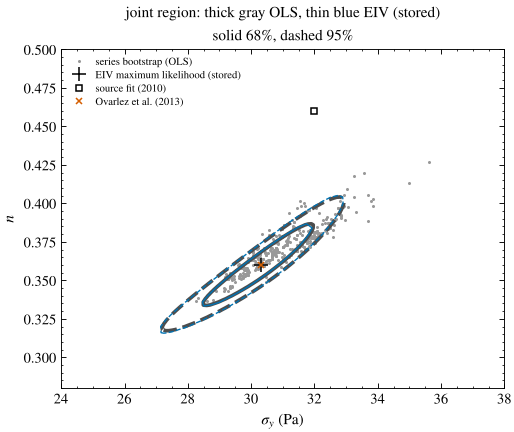

In [11]:
# Stored EIV joint profile deviance on the grid used for Fig. S1(c)
grid = pd.read_csv(FIGDATA / "figS1_foam_joint_deviance_grid.csv", comment="#")
SYe = grid.pivot(index="n", columns="sigma_y_Pa", values="profile_deviance")
fig, ax = plt.subplots(figsize=(5.2, 4))
cs = ax.contour(SY, NN, joint_dev, levels=[2.279, 5.991], colors="0.3", linestyles=["-", "--"], linewidths=2.4)
ax.contour(SYe.columns.to_numpy(), SYe.index.to_numpy(), SYe.to_numpy(), levels=[2.279, 5.991],
           colors=C["blue"], linestyles=["-", "--"], linewidths=0.9)
ax.plot(boot[:, 0], boot[:, 1], ".", ms=2, color="0.6", zorder=0, label="series bootstrap (OLS)")
ax.plot(sy_ml, n_ml, "k+", ms=9, label="EIV maximum likelihood (stored)")
ax.plot(32.0, 0.46, "s", mfc="white", mec="k", label="source fit (2010)")
ax.plot(30.3, 0.36, "x", color=C["red"], label="Ovarlez et al. (2013)")
ax.set(xlabel=r"$\sigma_y$ (Pa)", ylabel="$n$", xlim=(24, 38), ylim=(0.28, 0.50),
       title="joint region: thick gray OLS, thin blue EIV (stored)\nsolid 68%, dashed 95%")
ax.legend(fontsize=7, loc="upper left")
plt.show()

The thick gray contours are our OLS joint region, the thin blue ones the stored errors-in-variables region of Fig. S1(c) (`figS1_foam_joint_deviance_grid.csv`); they nearly coincide. The joint region is a long, tilted ellipse: $\sigma_y$ and $n$ are strongly correlated, so their marginal intervals are wide even though the curve itself is well determined. The source triplet (32 Pa, 0.46) is far outside the region (EIV deviance 138), although its $\sigma_y$ alone lies within the bootstrap range: it is the combination that the points reject. The values later quoted by Ovarlez et al. (2013), 30.3 Pa and 0.36, coincide with the maximum-likelihood estimate.

Note S2's interpretation: about ±7% on $\sigma_y$ and ±10% on $n$ is the uncertainty attached to an *excellent* local dataset spanning three decades in rate, **before** batch-to-batch variation is considered. The bootstrap is wider than the profile interval because points within one series are not independent. And none of these intervals contains systematic errors (Sec. VI E of the article), which usually dominate.

## 6. The critical shear rate

### What it means
In a **simple** yield-stress fluid the steady flow curve is unique and homogeneous flow is stable at all rates down to zero. In a **thixotropic** yield-stress fluid structure builds up at rest; below a critical shear rate $\dot\gamma_c$ no steady homogeneous flow exists. If a macroscopic rate below $\dot\gamma_c$ is imposed, the material bands: a fluidized layer shears at about $\dot\gamma_c$ while the rest is arrested, and the stress stays near its value at $\dot\gamma_c$ (article Sec. V B). For the foam, the film-instability model of Denkov et al. (2009b) predicts $\dot\gamma_c=1.5$ s$^{-1}$, whereas the MRI profiles bound it below about 0.04 s$^{-1}$ (no velocity-gradient discontinuity at the sheared–unsheared interface).

### How a flow curve bounds it
Note S2 adds the minimal banding alternative, the **HB-$\dot\gamma_c$ model**: the HB branch exists only for $\dot\gamma\ge\dot\gamma_c$, steady flow stops at the stress $\sigma_c=\sigma_y+K\dot\gamma_c^{\,n}$, and an observed local rate below $\dot\gamma_c$ can arise only from rate error. HB is its limit $\dot\gamma_c\to0$, so the profile likelihood of $\dot\gamma_c$ gives an upper bound directly. That computation (a latent rate profiled numerically for every point and every $\dot\gamma_c$) is the slowest part of the reanalysis, and we load its stored results.

In [12]:
gc = stored["HB_gc"]
gc_grid = np.array(gc["gc_grid_s_inv"])
print(f"95% upper bound on gamma_dot_c (baseline error model): {gc['upper_bound_95_s_inv']:.3f} 1/s")
print(f"deviance at the predicted 1.5 1/s: {gc['deviance_at_denkov_1.5']:.0f}")
print("\nsensitivity to the rate-error model:")
for sv in gc["sensitivity"]:
    print(f"  delta0 = {sv['rate_relative_sd']:.2f}, eps_g = {sv['rate_floor_sd_s_inv']:.3f} 1/s:  "
          f"bound {sv['upper_bound_95_s_inv']:.3f} 1/s, deviance at 1.5 1/s = {sv['deviance_at_denkov_1.5']:.0f}")
sy_c, K_c, n_c = stored["HB"]["parameters"]
for g_c in (gc["upper_bound_95_s_inv"], 1.5):
    print(f"stopping stress sigma_c = sigma_y + K gc^n at gc = {g_c:.3f} 1/s: {sy_c + K_c * g_c ** n_c:.1f} Pa")

95% upper bound on gamma_dot_c (baseline error model): 0.047 1/s
deviance at the predicted 1.5 1/s: 7659

sensitivity to the rate-error model:
  delta0 = 0.05, eps_g = 0.003 1/s:  bound 0.034 1/s, deviance at 1.5 1/s = 7793
  delta0 = 0.05, eps_g = 0.030 1/s:  bound 0.066 1/s, deviance at 1.5 1/s = 6732
  delta0 = 0.02, eps_g = 0.010 1/s:  bound 0.047 1/s, deviance at 1.5 1/s = 42504
  delta0 = 0.10, eps_g = 0.010 1/s:  bound 0.049 1/s, deviance at 1.5 1/s = 2199
stopping stress sigma_c = sigma_y + K gc^n at gc = 0.047 1/s: 35.7 Pa
stopping stress sigma_c = sigma_y + K gc^n at gc = 1.500 1/s: 49.1 Pa


The bound, $\dot\gamma_c<0.047$ s$^{-1}$, moves between 0.034 and 0.066 s$^{-1}$ as the assumed rate errors change, and is consistent with the source's own bound from the velocity profiles (0.04 s$^{-1}$). The predicted 1.5 s$^{-1}$ is excluded with deviance above 2000 under every error model tested.

### A back-of-the-envelope version
Why is the evidence so lopsided? If steady flow were impossible below $\dot\gamma_c$, every point observed at $\dot\gamma_i<\dot\gamma_c$ would have to be a point at a true rate of at least $\dot\gamma_c$, displaced by rate error. With the rate error of Eq. (S4) evaluated at $\dot\gamma_c$, each such point costs roughly
$$z_i^2=\frac{(\dot\gamma_c-\dot\gamma_i)^2}{(\delta_0\dot\gamma_c)^2+\epsilon_g^2}$$
in deviance. Summing $z_i^2$ ignores the refit of the curve and the stress mismatch, so it is only a rough estimate made for this notebook, not the article's calculation; but it captures the mechanism.

gc = 0.040 1/s:   1 points below, rough deviance      1.5
gc = 0.047 1/s:   2 points below, rough deviance      3.9
gc = 0.100 1/s:   5 points below, rough deviance     92.3
gc = 0.300 1/s:  12 points below, rough deviance   1334.9
gc = 1.500 1/s:  47 points below, rough deviance   7346.7
rough 95% bound: 0.047 1/s (stored, full model: 0.047)
rough bound without the single lowest point (0.027 1/s): 0.062 1/s


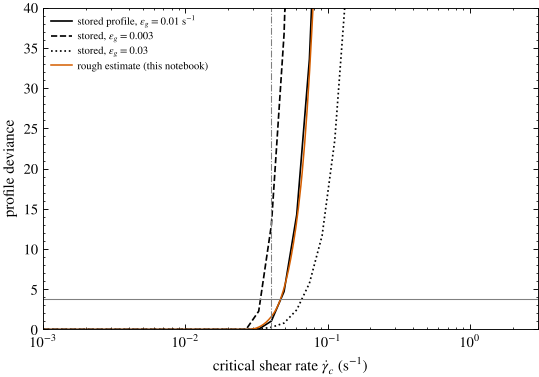

In [13]:
def rough_deviance(g_c, x=rate, d0=delta0, eps=eps_g):
    below = x < g_c
    return np.sum((g_c - x[below]) ** 2 / ((d0 * g_c) ** 2 + eps ** 2)), int(below.sum())

for g_c in (0.04, 0.047, 0.1, 0.3, 1.5):
    d, k = rough_deviance(g_c)
    print(f"gc = {g_c:5.3f} 1/s: {k:3d} points below, rough deviance {d:8.1f}")

g_scan = np.logspace(-3, np.log10(3), 400)
rough = np.array([rough_deviance(g)[0] for g in g_scan])
print(f"rough 95% bound: {g_scan[np.argmax(rough > 3.841)]:.3f} 1/s (stored, full model: {gc['upper_bound_95_s_inv']:.3f})")

# How much does the bound rest on the lowest point? Drop it and repeat the rough estimate.
keep = rate > rate.min()
rough_drop = np.array([rough_deviance(g, rate[keep])[0] for g in g_scan])
print(f"rough bound without the single lowest point ({rate.min():.3f} 1/s): {g_scan[np.argmax(rough_drop > 3.841)]:.3f} 1/s")

fig, ax = plt.subplots(figsize=(5.8, 3.8))
ax.semilogx(gc_grid, gc["profile_deviance"], "k-", label=r"stored profile, $\epsilon_g=0.01$ s$^{-1}$")
ax.semilogx(gc_grid, gc["sensitivity"][0]["deviance"], "k--", label=r"stored, $\epsilon_g=0.003$")
ax.semilogx(gc_grid, gc["sensitivity"][1]["deviance"], "k:", label=r"stored, $\epsilon_g=0.03$")
ax.semilogx(g_scan, rough, color=C["red"], lw=1, label="rough estimate (this notebook)")
ax.axhline(3.841, color="0.5", lw=0.7); ax.axvline(0.04, color="0.5", lw=0.7, ls="-.")
ax.set(xlabel=r"critical shear rate $\dot\gamma_c$ (s$^{-1}$)", ylabel="profile deviance", ylim=(0, 40), xlim=(1e-3, 3))
ax.legend(fontsize=7, loc="upper left"); plt.show()

At $\dot\gamma_c=1.5$ s$^{-1}$, 47 points would all have to be displaced by many standard deviations; the rough sum is several thousand, the same order as the stored deviance. At the other end the bound rests on very few points: only one point lies below 0.04 s$^{-1}$, and removing it raises even the rough bound noticeably. As Note S2 concludes, the flow curve cannot exclude a critical shear rate below the lowest resolved rate, nor a finite-viscosity continuation below it; that needs longer observation or finer velocimetry, not a better fit.

## 7. The limits of digitized data

The provenance and selection-audit files record how the points were obtained. Several limits follow.

In [14]:
prov = json.loads((DATA / "foam_digitization_provenance.json").read_text())
audit = json.loads((DATA / "foam_selection_audit.json").read_text())
print("status     :", prov["status"])
print("uncertainty:", prov["uncertainty"])
print("series     :", prov["group_meaning"])
print("audit      :", audit["interpretation"])

ax_cal = prov["axes"]
pt_per_decade = (ax_cal["x_at_10"] - ax_cal["x_at_0.01"]) / 3          # log-rate axis
pa_per_pt = 100 / (ax_cal["y_at_0_Pa"] - ax_cal["y_at_100_Pa"])        # linear stress axis
print(f"\nscale of the source figure: {pt_per_decade:.1f} pt per decade of rate "
      f"(1 pt = factor {10 ** (1 / pt_per_decade):.3f} in rate), {pa_per_pt:.3f} Pa per pt")
print(f"closest pair of marker centers: {audit['minimum_centre_distance_PDF_pt']:.3f} pt apart")

status     : Coordinates of published vector markers; not original raw MRI/torque data.
uncertainty: No experimental covariance or error bars recoverable. Coordinate perturbation is only a digitisation sensitivity.
series     : Marker shape identifies an acquisition series; speeds are not assigned because Fig. 3 has no speed legend.
audit      : No points removed on proximity alone; different marker groups can overlap. Raw-data independence is unresolved.

scale of the source figure: 37.6 pt per decade of rate (1 pt = factor 1.063 in rate), 0.974 Pa per pt
closest pair of marker centers: 0.028 pt apart


* **Plot-derived values.** They are the coordinates of the published markers, not the raw MRI and torque data. Any rounding or smoothing done before plotting is inherited.
* **No error bars or covariance.** The noise level has to be estimated from the scatter, and the rate-error model of Eq. (S4) is an assumption, which is why Note S2 reports how the $\dot\gamma_c$ bound changes with it.
* **Unknown series meaning.** Marker shapes identify acquisition series, but not which rotation rate or shear history each one is.
* **Possible hidden points.** Markers overlap in the source figure (the closest pair of centers is 0.03 pt apart), so points exactly hidden behind others cannot be recovered.
* **Dependence.** Points from one velocity profile share a sample, a cell and a calibration; they are not independent, hence the series bootstrap.

The digitization itself is precise: the markers are vector graphics, so the centers are known far better than a point. A quick sensitivity test makes this concrete: jitter every center by a Gaussian error with standard deviation 0.1 pt in both directions (a pessimistic value for vector markers) and refit.

In [15]:
rng = np.random.default_rng(7)
jitter_fits = []
for _ in range(200):
    lr = np.log10(rate) + rng.normal(0, 0.1, N) / pt_per_decade        # 0.1 pt on the log-rate axis
    st = stress + rng.normal(0, 0.1, N) * pa_per_pt                    # 0.1 pt on the stress axis
    r1 = minimize_scalar(lambda nn: linear_fit_at_n(nn, 10 ** lr, st)[1], bounds=(0.1, 0.8), method="bounded",
                         options={"xatol": 1e-7})
    jitter_fits.append([linear_fit_at_n(r1.x, 10 ** lr, st)[0][0], r1.x])
jitter_fits = np.array(jitter_fits)
print("SD of the OLS estimates under 0.1-pt digitization jitter: sigma_y %.3f Pa, n %.4f" % tuple(jitter_fits.std(axis=0)))
print("for comparison, half-width of the 95%% profile interval: sigma_y %.2f Pa, n %.3f" % (
    np.diff(stored["HB"]["profile_95_sigma_y_Pa"])[0] / 2, np.diff(stored["HB"]["profile_95_n"])[0] / 2))

SD of the OLS estimates under 0.1-pt digitization jitter: sigma_y 0.073 Pa, n 0.0012
for comparison, half-width of the 95% profile interval: sigma_y 2.12 Pa, n 0.035


Digitization noise is negligible next to the statistical uncertainty, which in turn is a lower bound on the real uncertainty. The limits that matter are those of the published figure, not of the digitizer.

## 8. Reproducing Fig. S1 and checking it against the figure data

We redraw the three panels from the digitized points and the stored results. Panel (c) shows contours of the EIV joint profile deviance; the deviance grid behind them is stored in `figS1_foam_joint_deviance_grid.csv`, and the plotted points of that panel (maximum-likelihood estimate, source fit, 400 bootstrap fits) in `figS1_foam.csv`.

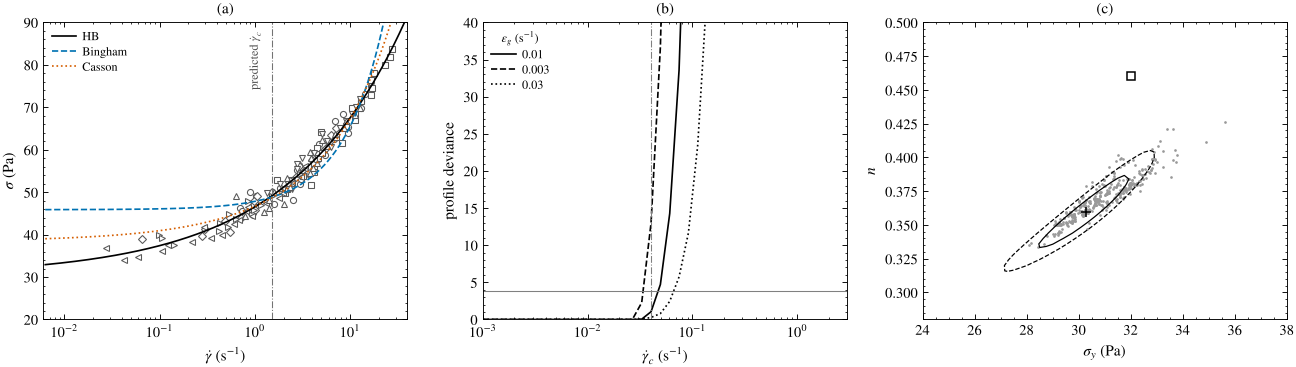

In [16]:
fits_stored = {name: stored[name]["parameters"] for name in ("HB", "Bingham", "Casson")}
FUN = {"HB": f_hb, "Bingham": f_bingham, "Casson": f_casson}
xx = np.logspace(-2.2, 1.6, 400)                              # grid of the script

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
plot_points(ax[0])
for name, (col, ls) in zip(fits_stored, [("k", "-"), (C["blue"], "--"), (C["red"], ":")]):
    ax[0].semilogx(xx, FUN[name](fits_stored[name], xx), color=col, ls=ls, label=name)
ax[0].axvline(1.5, color="0.45", lw=0.7, ls="-.")
ax[0].text(1.2, 88, r"predicted $\dot\gamma_c$", fontsize=8, ha="right", va="top", rotation=90, color="0.3")
h, l = ax[0].get_legend_handles_labels(); ax[0].legend(h[-3:], l[-3:], fontsize=8, loc="upper left")
ax[0].set(xlim=(6e-3, 40), ylim=(20, 90), xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", title="(a)")
ax[1].semilogx(gc_grid, gc["profile_deviance"], "k-", label="0.01")
for sv, ls in zip(gc["sensitivity"][:2], ["--", ":"]):
    ax[1].semilogx(gc_grid, sv["deviance"], "k", ls=ls, label=f"{sv['rate_floor_sd_s_inv']:g}")
ax[1].axhline(3.841, color="0.5", lw=0.7); ax[1].axvline(0.04, color="0.5", lw=0.7, ls="-.")
ax[1].set(ylim=(0, 40), xlim=(1e-3, 3), xlabel=r"$\dot\gamma_c$ (s$^{-1}$)", ylabel="profile deviance", title="(b)")
ax[1].legend(fontsize=8, title=r"$\epsilon_g$ (s$^{-1}$)", title_fontsize=8, loc="upper left")
fd = pd.read_csv(FIGDATA / "figS1_foam.csv", comment="#")
boot_csv = fd[(fd["panel"] == "(c)") & (fd["series"] == "block-bootstrap fits (sigma_y, n)")]
ax[2].contour(SYe.columns.to_numpy(), SYe.index.to_numpy(), SYe.to_numpy(), levels=[2.279, 5.991],
              colors="k", linestyles=["-", "--"], linewidths=0.8)
ax[2].plot(boot_csv["x"], boot_csv["y"], ".", ms=1.5, color="0.6", zorder=0)
ax[2].plot(sy_ml, n_ml, "k+", ms=7)
ax[2].plot(32.0, 0.46, "s", mfc="white", mec="k", ms=5)
ax[2].set(xlim=(24, 38), ylim=(0.28, 0.50), xlabel=r"$\sigma_y$ (Pa)", ylabel="$n$", title="(c)")
fig.tight_layout(); plt.show()

In [17]:
RTOL = 1e-8
# (a) the digitized points: each marker series of the figure is one acquisition series of the CSV
assert len(fd[(fd["panel"] == "(a)") & (fd["kind"] == "markers")]) == N
for name in series_names:
    x, y = figure_series(fd, "(a)", f"digitized points, marker group {name}")
    sel = group == name
    assert np.allclose(x, rate[sel], rtol=RTOL) and np.allclose(y, stress[sel], rtol=RTOL), name
# (a) the three fitted curves from the stored parameters
for name in fits_stored:
    x, y = figure_series(fd, "(a)", name)
    assert np.allclose(x, xx, rtol=RTOL) and np.allclose(y, FUN[name](fits_stored[name], xx), rtol=RTOL), name
assert np.isclose(fd.loc[fd["series"] == "predicted critical shear rate", "x"].item(), 1.5)
# (b) profile deviance curves against the stored JSON
for floor, dev in [("0.01", gc["profile_deviance"]), ("0.003", gc["sensitivity"][0]["deviance"]),
                   ("0.03", gc["sensitivity"][1]["deviance"])]:
    x, y = figure_series(fd, "(b)", f"profile deviance, rate floor {floor} 1/s")
    assert np.allclose(x, gc_grid, rtol=RTOL) and np.allclose(y, dev, rtol=RTOL, atol=1e-8), floor
assert np.isclose(fd.loc[fd["series"] == "95% threshold (chi-squared, 1 dof)", "y"].item(), 3.841, atol=1e-3)
assert np.isclose(fd.loc[fd["series"] == "bound on critical shear rate reported by the source", "x"].item(), 0.04)
# (c) ML estimate, source fit, bootstrap quantiles and the deviance grid
x, y = figure_series(fd, "(c)", "maximum-likelihood estimate (sigma_y, n)")
assert np.allclose([x[0], y[0]], [sy_ml, n_ml], rtol=RTOL)
x, y = figure_series(fd, "(c)", "fit reported by the source")
assert np.allclose([x[0], y[0]], [32.0, 0.46])
assert len(boot_csv) == stored["HB"]["series_bootstrap_replicates"]
assert np.allclose(np.quantile(boot_csv["x"], [0.025, 0.975]), stored["HB"]["series_bootstrap_95_sigma_y_Pa"], rtol=1e-7)
assert np.allclose(np.quantile(boot_csv["y"], [0.025, 0.975]), stored["HB"]["series_bootstrap_95_n"], rtol=1e-7)
assert len(grid) == 57 * 56 and grid["profile_deviance"].min() < 0.05     # grid minimum sits at the ML estimate
# our OLS fit against the stored EIV estimate (different estimators: agreement to 0.5% is expected, not exact)
assert np.allclose(ols["HB"]["p"], stored["HB"]["parameters"], rtol=5e-3)
print("Fig. S1 check passed: 152 points (7 series), 3 fitted curves, 3 deviance profiles, the ML estimate, "
      "the source fit and the 400 bootstrap fits agree with figS1_foam.csv and foam_reanalysis_results.json "
      "(and the 57 x 56 deviance grid is present) "
      f"(relative tolerance {RTOL:g}); our OLS HB triplet is within 0.5% of the stored EIV estimate.")

Fig. S1 check passed: 152 points (7 series), 3 fitted curves, 3 deviance profiles, the ML estimate, the source fit and the 400 bootstrap fits agree with figS1_foam.csv and foam_reanalysis_results.json (and the 57 x 56 deviance grid is present) (relative tolerance 1e-08); our OLS HB triplet is within 0.5% of the stored EIV estimate.


## Try it yourself

**Exercise 1 — relative errors.** Refit HB minimizing $\sum_i[\ln\sigma_i-\ln f(\dot\gamma_i)]^2$ (logarithmic residuals, i.e. constant *relative* error). Does the triplet move outside the 95% profile interval?
*Hint:* change the residual function passed to `least_squares`.

**Exercise 2 — the source exponent.** Fix $n=0.46$, fit $\sigma_y$ and $K$ by linear least squares, and compare the RMSE and the residual pattern with the free fit. Is the difference visible by eye in a plot of the curve? In the residuals?
*Hint:* `linear_fit_at_n(0.46)`.

**Exercise 3 — prediction of withheld series.** Fit HB to six series and predict the seventh, for each series in turn, and compute the RMSE of the predictions. Note S2 reports 1.83 Pa for this test with the EIV fit (against 1.77 Pa for the full fit).

**Exercise 4 — a tighter rate floor.** Using the rough estimate of Sec. 6, how does the bound on $\dot\gamma_c$ change if $\epsilon_g=0.003$ s$^{-1}$? Compare with the stored value for that error model.

<details><summary>Solutions (click to expand)</summary>

1. Logarithmic residuals give $\sigma_y\approx30.8$ Pa, $K\approx15.7$ Pa s$^n$ and $n\approx0.369$, inside the profile intervals: with stresses between 34 and 84 Pa the weighting changes little here.
2. With $n=0.46$, $\sigma_y\approx35.3$ Pa and $K\approx11.2$ Pa s$^n$; the RMSE rises only from 1.77 to 1.94 Pa, yet the profile deviance is about 27, far beyond 3.84. The two curves are hard to tell apart by eye in the data window; the residuals show the systematic pattern. This is the identifiability problem of Sec. VI D.
3. About 1.83 Pa, close to the in-sample RMSE (Note S2: 1.83 against 1.77 Pa). Series share sample, cell and calibration, so withholding a series is a weak validation.
4. The rough bound falls to about 0.034 s$^{-1}$, the same as the stored value for that error model.
</details>

In [18]:
# Optional solution code (uncomment to run)
# # 1
# r_log = least_squares(lambda p: np.log(f_hb(p, rate)) - np.log(stress), [30, 15, 0.4], bounds=([0, 1e-6, 0.05], [200, 500, 2]))
# print(r_log.x)
# # 2
# (sy46, K46), rss46 = linear_fit_at_n(0.46)
# print(sy46, K46, np.sqrt(rss46 / N), N * np.log(rss46 / rss_n.min()))
# # 3
# pred = np.empty(N)
# for q in series_names:
#     tr = group != q
#     r1 = minimize_scalar(lambda nn: linear_fit_at_n(nn, rate[tr], stress[tr])[1], bounds=(0.1, 0.8), method="bounded")
#     (a, b), _ = linear_fit_at_n(r1.x, rate[tr], stress[tr])
#     pred[~tr] = a + b * rate[~tr] ** r1.x
# print(np.sqrt(np.mean((pred - stress) ** 2)))
# # 4
# rough3 = np.array([rough_deviance(g, eps=0.003)[0] for g in g_scan])
# print(g_scan[np.argmax(rough3 > 3.841)], stored["HB_gc"]["sensitivity"][0]["upper_bound_95_s_inv"])

## Key points
* The local flow curve of this foam is concave and is described far better by HB than by Bingham or Casson ($\Delta$AIC about 90 and 270); the Bingham intercept is inflated by about 50%.
* At fixed $n$ the HB fit is linear; the resulting profile exposes a long $\sigma_y$–$n$ valley. Even for an excellent dataset over three decades, the 95% ranges are about ±7% on $\sigma_y$ and ±10% on $n$, before batch-to-batch and systematic errors.
* The errors-in-variables model of Note S2, Eq. (S4), barely changes the HB estimate here ($\sigma_y=30.3$ Pa, $K=16.3$ Pa s$^n$, $n=0.360$) but is essential for questions decided by the lowest rates.
* A critical shear rate is the rate below which no steady homogeneous flow exists. The flow curve alone bounds it below about 0.05 s$^{-1}$, consistent with the source's 0.04 s$^{-1}$, and rejects the predicted 1.5 s$^{-1}$ decisively; it cannot exclude a $\dot\gamma_c$ below the lowest measured rate.
* Digitized points carry no error bars, unknown series labels and possible hidden markers; the digitization error itself is negligible. Cite the original source when reusing such values.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Bingham, E. C. (1916). An investigation of the laws of plastic flow. *Bulletin of the Bureau of Standards* **13**(2), 309–353. https://doi.org/10.6028/bulletin.304
* Casson, N. (1959). A flow equation for pigment-oil suspensions of the printing ink type. In C. C. Mill (ed.), *Rheology of Disperse Systems*, pp. 84–104. Pergamon Press, London.
* Denkov, N. D., Tcholakova, S., Golemanov, K., Ananthpadmanabhan, K. P., and Lips, A. (2009a). The role of surfactant type and bubble surface mobility in foam rheology. *Soft Matter* **5**(18), 3389. https://doi.org/10.1039/b903586a
* Denkov, N. D., Tcholakova, S., Golemanov, K., and Lips, A. (2009b). Jamming in sheared foams and emulsions, explained by critical instability of the films between neighboring bubbles and drops. *Physical Review Letters* **103**(11), 118302. https://doi.org/10.1103/PhysRevLett.103.118302
* Herschel, W. H., and Bulkley, R. (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**(4), 291–300. https://doi.org/10.1007/bf01432034
* Mullineux, G. (2008). Non-linear least squares fitting of coefficients in the Herschel–Bulkley model. *Applied Mathematical Modelling* **32**(12), 2538–2551. https://doi.org/10.1016/j.apm.2007.09.010
* Ovarlez, G., Krishan, K., and Cohen-Addad, S. (2010). Investigation of shear banding in three-dimensional foams. *EPL* **91**, 68005. https://doi.org/10.1209/0295-5075/91/68005 (data digitized from Fig. 3b of arXiv:1007.4133v2)
* Ovarlez, G., Cohen-Addad, S., Krishan, K., Goyon, J., and Coussot, P. (2013). On the existence of a simple yield stress fluid behavior. *Journal of Non-Newtonian Fluid Mechanics* **193**, 68–79. https://doi.org/10.1016/j.jnnfm.2012.06.009

### Further reading

* Freund, J. B., and Ewoldt, R. H. (2015). Quantitative rheological model selection: Good fits versus credible models using Bayesian inference. *Journal of Rheology* **59**(3), 667–701. https://doi.org/10.1122/1.4915299